    Study_Hours  Attendance  Assignment_marks  Internal_marks  Pratical_marks  \
0             1          50                30              25              28   
1             2          55                35              30              32   
2             2          60                32              28              30   
3             3          58                38              32              35   
4             2          52                33              27              29   
5             3          62                40              35              37   
6             1          48                28              24              25   
7             2          57                36              31              33   
8             3          63                39              29              36   
9             2          54                34              28              31   
10            4          70                50              45              48   
11            5          75 

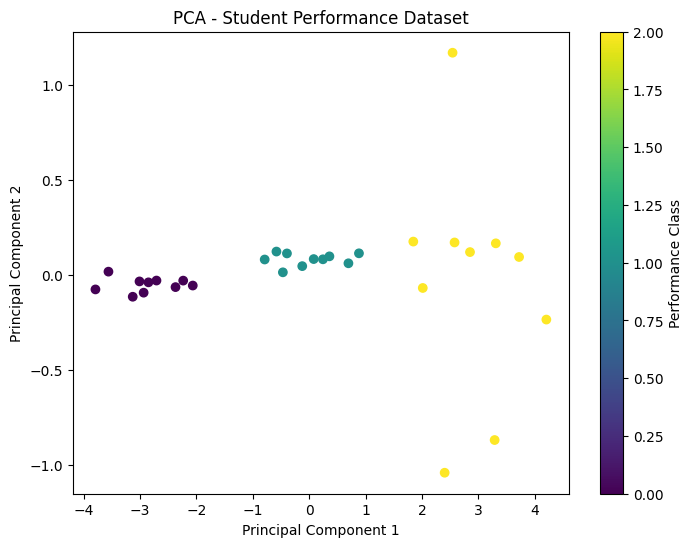

Original shape: (30, 6)
Reduced shape: (30, 2)


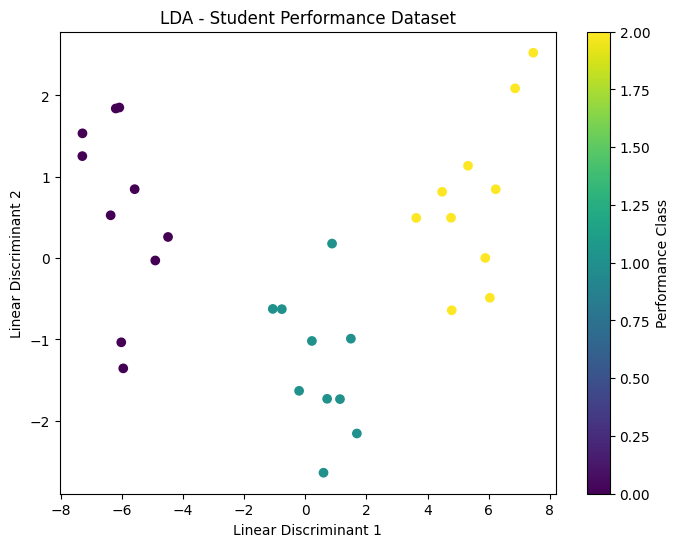

In [16]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

data={
    'Study_Hours':[1,2,2,3,2,3,1,2,3,2,
                   4,5,4,5,6,4,5,6,5,4,
                   7,8,7,9,8,7,9,8,10,9],
    'Attendance':[50,55,60,58,52,62,48,57,63,54,
                  70,75,72,78,80,74,76,82,79,73,
                  85,90,88,95,92,87,96,91,98,94],
    'Assignment_marks':[30,35,32,38,33,40,28,36,39,34,
                        50,55,52,58,60,54,57,62,59,53,
                        70,75,72,80,78,73,85,79,90,86],
    'Internal_marks':[25,30,28,32,27,35,24,31,29,28,
                      45,48,46,52,56,47,50,56,53,49,
                      65,70,68,75,73,67,80,74,85,82],
    'Pratical_marks':[28,32,30,35,29,37,25,33,36,31,
                      48,52,50,55,58,51,54,60,56,49,
                     68,73,65,78,74,89,61,52,78,80],
    'Test_makrs':[20,25,22,28,24,30,18,26,29,23,
                  40,45,42,48,50,44,47,52,49,43,
                  60,65,62,70,68,63,75,69,80,75],
    'Performance':[0,0,0,0,0,0,0,0,0,0,
                   1,1,1,1,1,1,1,1,1,1,
                   2,2,2,2,2,2,2,2,2,2]
}

#
df=pd.DataFrame(data)
print(df)
X=df.drop('Performance',axis=1)
y=df['Performance']
print("Input shape:",X.shape)
print("output shape:",y.shape)

#standardized the input features
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
print("Standardized data:")
print(X_scaled[:5])

#reduce six features into two components
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)
print("Original shape:",X_scaled.shape)
print("Reduced shape:",X_pca.shape)

#dispaly explained variance
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)
print("Total explianed variance:")
print(sum(pca.explained_variance_ratio_))

#visualize PCA results
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=y,
    cmap='viridis'
)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA - Student Performance Dataset')
plt.colorbar(label='Performance Class')
plt.show()

#reduce six feautres into two discriminants
lda=LinearDiscriminantAnalysis(n_components=2)
X_lda=lda.fit_transform(X_scaled,y)
print("Original shape:",X_scaled.shape)
print("Reduced shape:",X_lda.shape)

#visualize lad results
plt.figure(figsize=(8,6))
plt.scatter(
    X_lda[:,0],
    X_lda[:,1],
    c=y,
    cmap='viridis'
)
plt.xlabel("Linear Discriminant 1")
plt.ylabel("Linear Discriminant 2")
plt.title("LDA - Student Performance Dataset")
plt.colorbar(label="Performance Class")
plt.show()


